In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load the water consumption dataset

df = pd.read_csv("waterconsumption_noNaN_fixedTimechange.csv")

# Display first 5 records
df.head()

,Date,Time,Consumption,Temperature,Rain,Sun
0,1/1/2016,00:00-01:00,1480,0.6,0.0,0
1,1/1/2016,01:00-02:00,1362,0.6,0.0,0
2,1/1/2016,02:00-03:00,1296,0.5,0.0,0
3,1/1/2016,03:00-04:00,1096,0.0,0.0,0
4,1/1/2016,04:00-05:00,810,0.3,0.0,0


In [3]:
# Check number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

Dataset Shape: (46032, 6)

Column Names:
['Date', 'Time', 'Consumption', 'Temperature', 'Rain', 'Sun']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46032 entries, 0 to 46031
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         46032 non-null  object 
 1   Time         46032 non-null  object 
 2   Consumption  46032 non-null  int64  
 3   Temperature  46032 non-null  float64
 4   Rain         46007 non-null  float64
 5   Sun          46032 non-null  int64  
dtypes: float64(2), int64(2), object(2)
memory usage: 2.1+ MB

Statistical Summary:


,Consumption,Temperature,Rain,Sun
count,46032.000000,46032.000000,46007.000000,46032.000000
mean,2314.342544,10.799741,0.050079,1.677333
std,1032.138095,7.763414,0.375667,2.883667
min,1.000000,-17.600000,0.000000,0.000000
25%,1461.000000,5.000000,0.000000,0.000000
50%,2550.000000,10.100000,0.000000,0.000000
75%,3082.000000,16.200000,0.000000,2.000000
max,6514.000000,40.300000,22.000000,20.000000


In [4]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

# Calculate missing value percentage
print("\nMissing Value Percentage:")

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Missing Values:
Date            0
Time            0
Consumption     0
Temperature     0
Rain           25
Sun             0
dtype: int64

Missing Value Percentage:
Date           0.00000
Time           0.00000
Consumption    0.00000
Temperature    0.00000
Rain           0.05431
Sun            0.00000
dtype: float64


In [5]:
# Fill missing Rain values with median

rain_median = df['Rain'].median()

df['Rain'] = df['Rain'].fillna(rain_median)

# Verify missing values
print("Missing values after treatment:")
print(df.isnull().sum())

print("\nRain median used:", rain_median)

Missing values after treatment:
Date           0
Time           0
Consumption    0
Temperature    0
Rain           0
Sun            0
dtype: int64

Rain median used: 0.0


In [6]:
# Display first 10 Date and Time values

df[['Date', 'Time']].head(10)

,Date,Time
0,1/1/2016,00:00-01:00
1,1/1/2016,01:00-02:00
2,1/1/2016,02:00-03:00
3,1/1/2016,03:00-04:00
4,1/1/2016,04:00-05:00
5,1/1/2016,05:00-06:00
6,1/1/2016,06:00-07:00
7,1/1/2016,07:00-08:00
8,1/1/2016,08:00-09:00
9,1/1/2016,09:00-10:00


In [8]:
# Extract starting hour from Time column
df['Hour'] = df['Time'].str.split('-').str[0]

# Combine Date and Hour into Datetime
df['Datetime'] = pd.to_datetime(
    df['Date'] + ' ' + df['Hour'],
    format='%m/%d/%Y %H:%M'
)

# Display the result
df[['Date', 'Time', 'Hour', 'Datetime']].head(10)

,Date,Time,Hour,Datetime
0,1/1/2016,00:00-01:00,00:00,2016-01-01 00:00:00
1,1/1/2016,01:00-02:00,01:00,2016-01-01 01:00:00
2,1/1/2016,02:00-03:00,02:00,2016-01-01 02:00:00
3,1/1/2016,03:00-04:00,03:00,2016-01-01 03:00:00
4,1/1/2016,04:00-05:00,04:00,2016-01-01 04:00:00
5,1/1/2016,05:00-06:00,05:00,2016-01-01 05:00:00
6,1/1/2016,06:00-07:00,06:00,2016-01-01 06:00:00
7,1/1/2016,07:00-08:00,07:00,2016-01-01 07:00:00
8,1/1/2016,08:00-09:00,08:00,2016-01-01 08:00:00
9,1/1/2016,09:00-10:00,09:00,2016-01-01 09:00:00


In [9]:
# Check first and last timestamps
print("First timestamp:", df['Datetime'].min())
print("Last timestamp:", df['Datetime'].max())

# Check whether data is already in chronological order
print("Is data sorted:", df['Datetime'].is_monotonic_increasing)

# Check duplicate timestamps
print("Duplicate timestamps:", df['Datetime'].duplicated().sum())

First timestamp: 2016-01-01 00:00:00
Last timestamp: 2021-04-01 23:00:00
Is data sorted: True
Duplicate timestamps: 0


In [10]:
# Sort data by Datetime
df = df.sort_values(by='Datetime')

# Reset index
df = df.reset_index(drop=True)

# Verify the result
print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
display(df.head())

Dataset Shape: (46032, 8)

First 5 records:


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Datetime
0,1/1/2016,00:00-01:00,1480,0.6,0.0,0,00:00,2016-01-01 00:00:00
1,1/1/2016,01:00-02:00,1362,0.6,0.0,0,01:00,2016-01-01 01:00:00
2,1/1/2016,02:00-03:00,1296,0.5,0.0,0,02:00,2016-01-01 02:00:00
3,1/1/2016,03:00-04:00,1096,0.0,0.0,0,03:00,2016-01-01 03:00:00
4,1/1/2016,04:00-05:00,810,0.3,0.0,0,04:00,2016-01-01 04:00:00


In [11]:
# Extract time-based features

df['Year'] = df['Datetime'].dt.year
df['Month'] = df['Datetime'].dt.month
df['Day'] = df['Datetime'].dt.day
df['DayOfWeek'] = df['Datetime'].dt.dayofweek
df['Hour_Number'] = df['Datetime'].dt.hour

# Display new features
display(df[['Datetime', 'Year', 'Month', 'Day',
            'DayOfWeek', 'Hour_Number']].head(10))

,Datetime,Year,Month,Day,DayOfWeek,Hour_Number
0,2016-01-01 00:00:00,2016,1,1,4,0
1,2016-01-01 01:00:00,2016,1,1,4,1
2,2016-01-01 02:00:00,2016,1,1,4,2
3,2016-01-01 03:00:00,2016,1,1,4,3
4,2016-01-01 04:00:00,2016,1,1,4,4
5,2016-01-01 05:00:00,2016,1,1,4,5
6,2016-01-01 06:00:00,2016,1,1,4,6
7,2016-01-01 07:00:00,2016,1,1,4,7
8,2016-01-01 08:00:00,2016,1,1,4,8
9,2016-01-01 09:00:00,2016,1,1,4,9


In [12]:
# Create weekend feature
# Saturday = 5, Sunday = 6

df['IsWeekend'] = df['DayOfWeek'].apply(
    lambda x: 1 if x >= 5 else 0
)

# Display the results
display(df[['Datetime', 'DayOfWeek', 'IsWeekend']].head(10))

# Count weekdays and weekends
print("\nWeekend Distribution:")
print(df['IsWeekend'].value_counts())

,Datetime,DayOfWeek,IsWeekend
0,2016-01-01 00:00:00,4,0
1,2016-01-01 01:00:00,4,0
2,2016-01-01 02:00:00,4,0
3,2016-01-01 03:00:00,4,0
4,2016-01-01 04:00:00,4,0
5,2016-01-01 05:00:00,4,0
6,2016-01-01 06:00:00,4,0
7,2016-01-01 07:00:00,4,0
8,2016-01-01 08:00:00,4,0
9,2016-01-01 09:00:00,4,0



Weekend Distribution:
IsWeekend
0    32880
1    13152
Name: count, dtype: int64


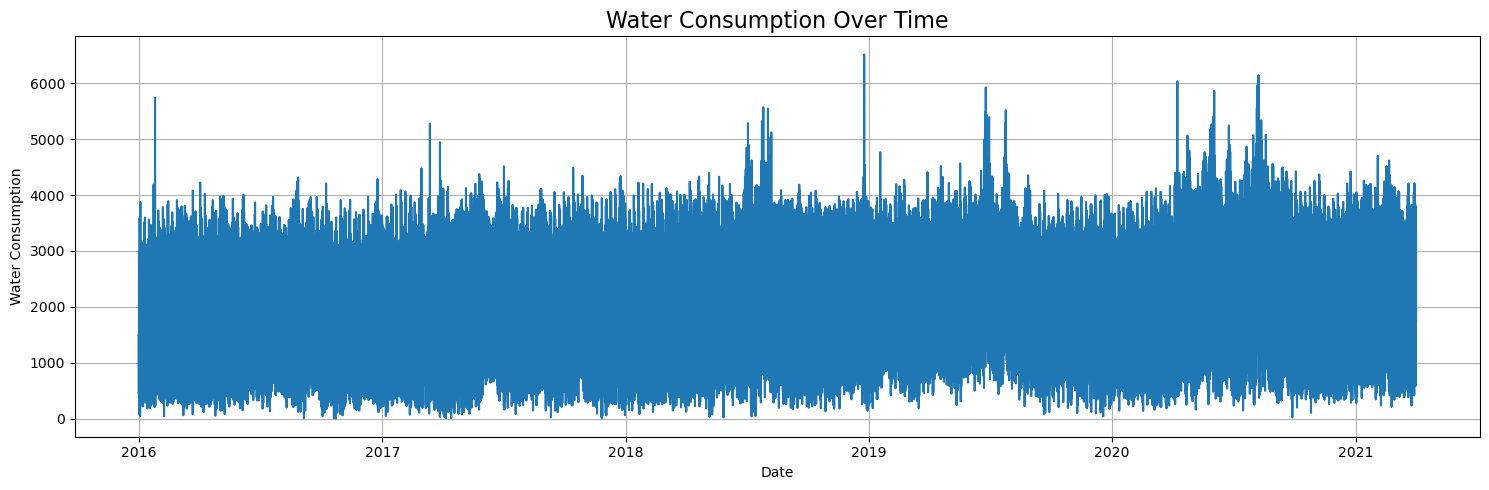

In [13]:
# Plot water consumption over time

plt.figure(figsize=(15, 5))

plt.plot(df['Datetime'], df['Consumption'])

plt.title('Water Consumption Over Time',
          fontsize=16)

plt.xlabel('Date')
plt.ylabel('Water Consumption')

plt.grid(True)
plt.tight_layout()
plt.show()

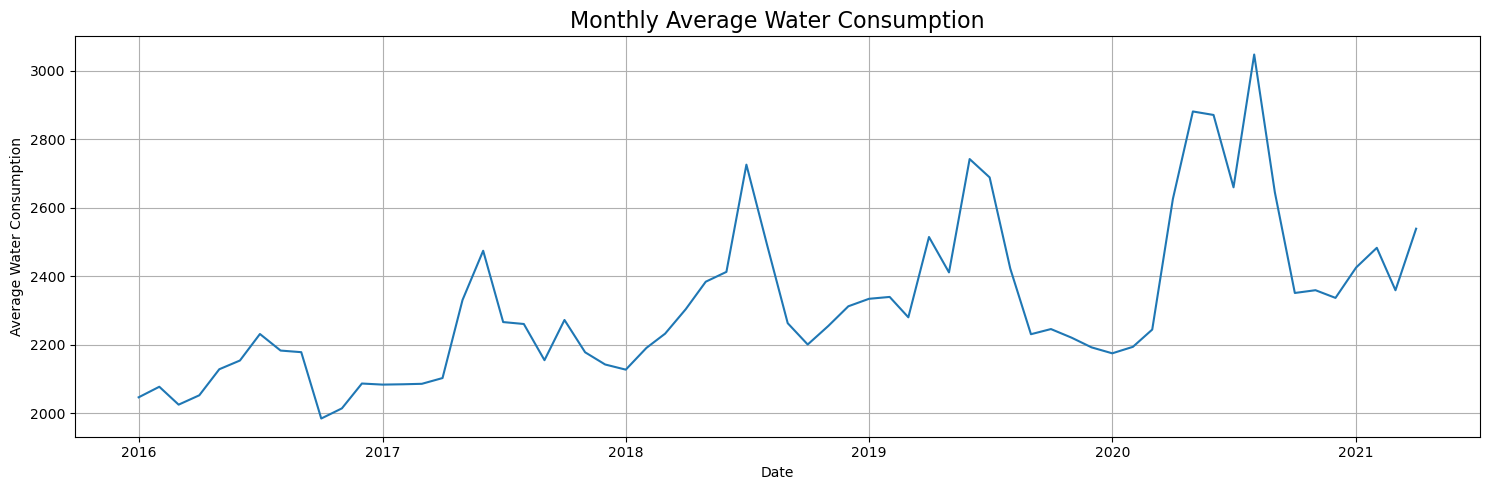

In [14]:
# Calculate monthly average consumption

monthly_consumption = df.set_index('Datetime')['Consumption'].resample('MS').mean()

# Plot monthly average consumption

plt.figure(figsize=(15, 5))

plt.plot(monthly_consumption.index, monthly_consumption.values)

plt.title('Monthly Average Water Consumption',
          fontsize=16)

plt.xlabel('Date')
plt.ylabel('Average Water Consumption')

plt.grid(True)
plt.tight_layout()
plt.show()

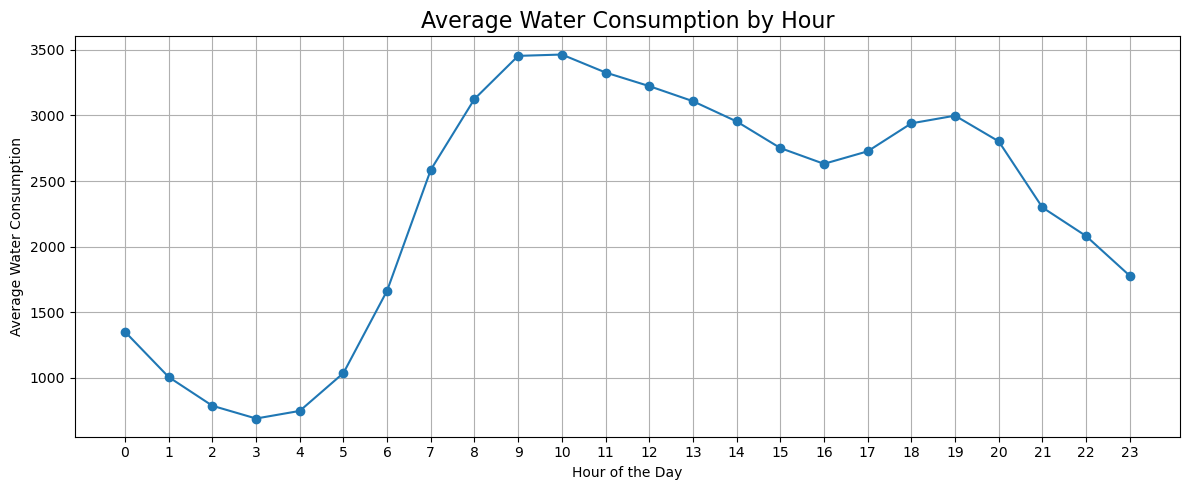

In [15]:
# Calculate average consumption for each hour

hourly_consumption = df.groupby('Hour_Number')['Consumption'].mean()

# Plot hourly average consumption

plt.figure(figsize=(12, 5))

plt.plot(hourly_consumption.index,
         hourly_consumption.values,
         marker='o')

plt.title('Average Water Consumption by Hour',
          fontsize=16)

plt.xlabel('Hour of the Day')
plt.ylabel('Average Water Consumption')

plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()

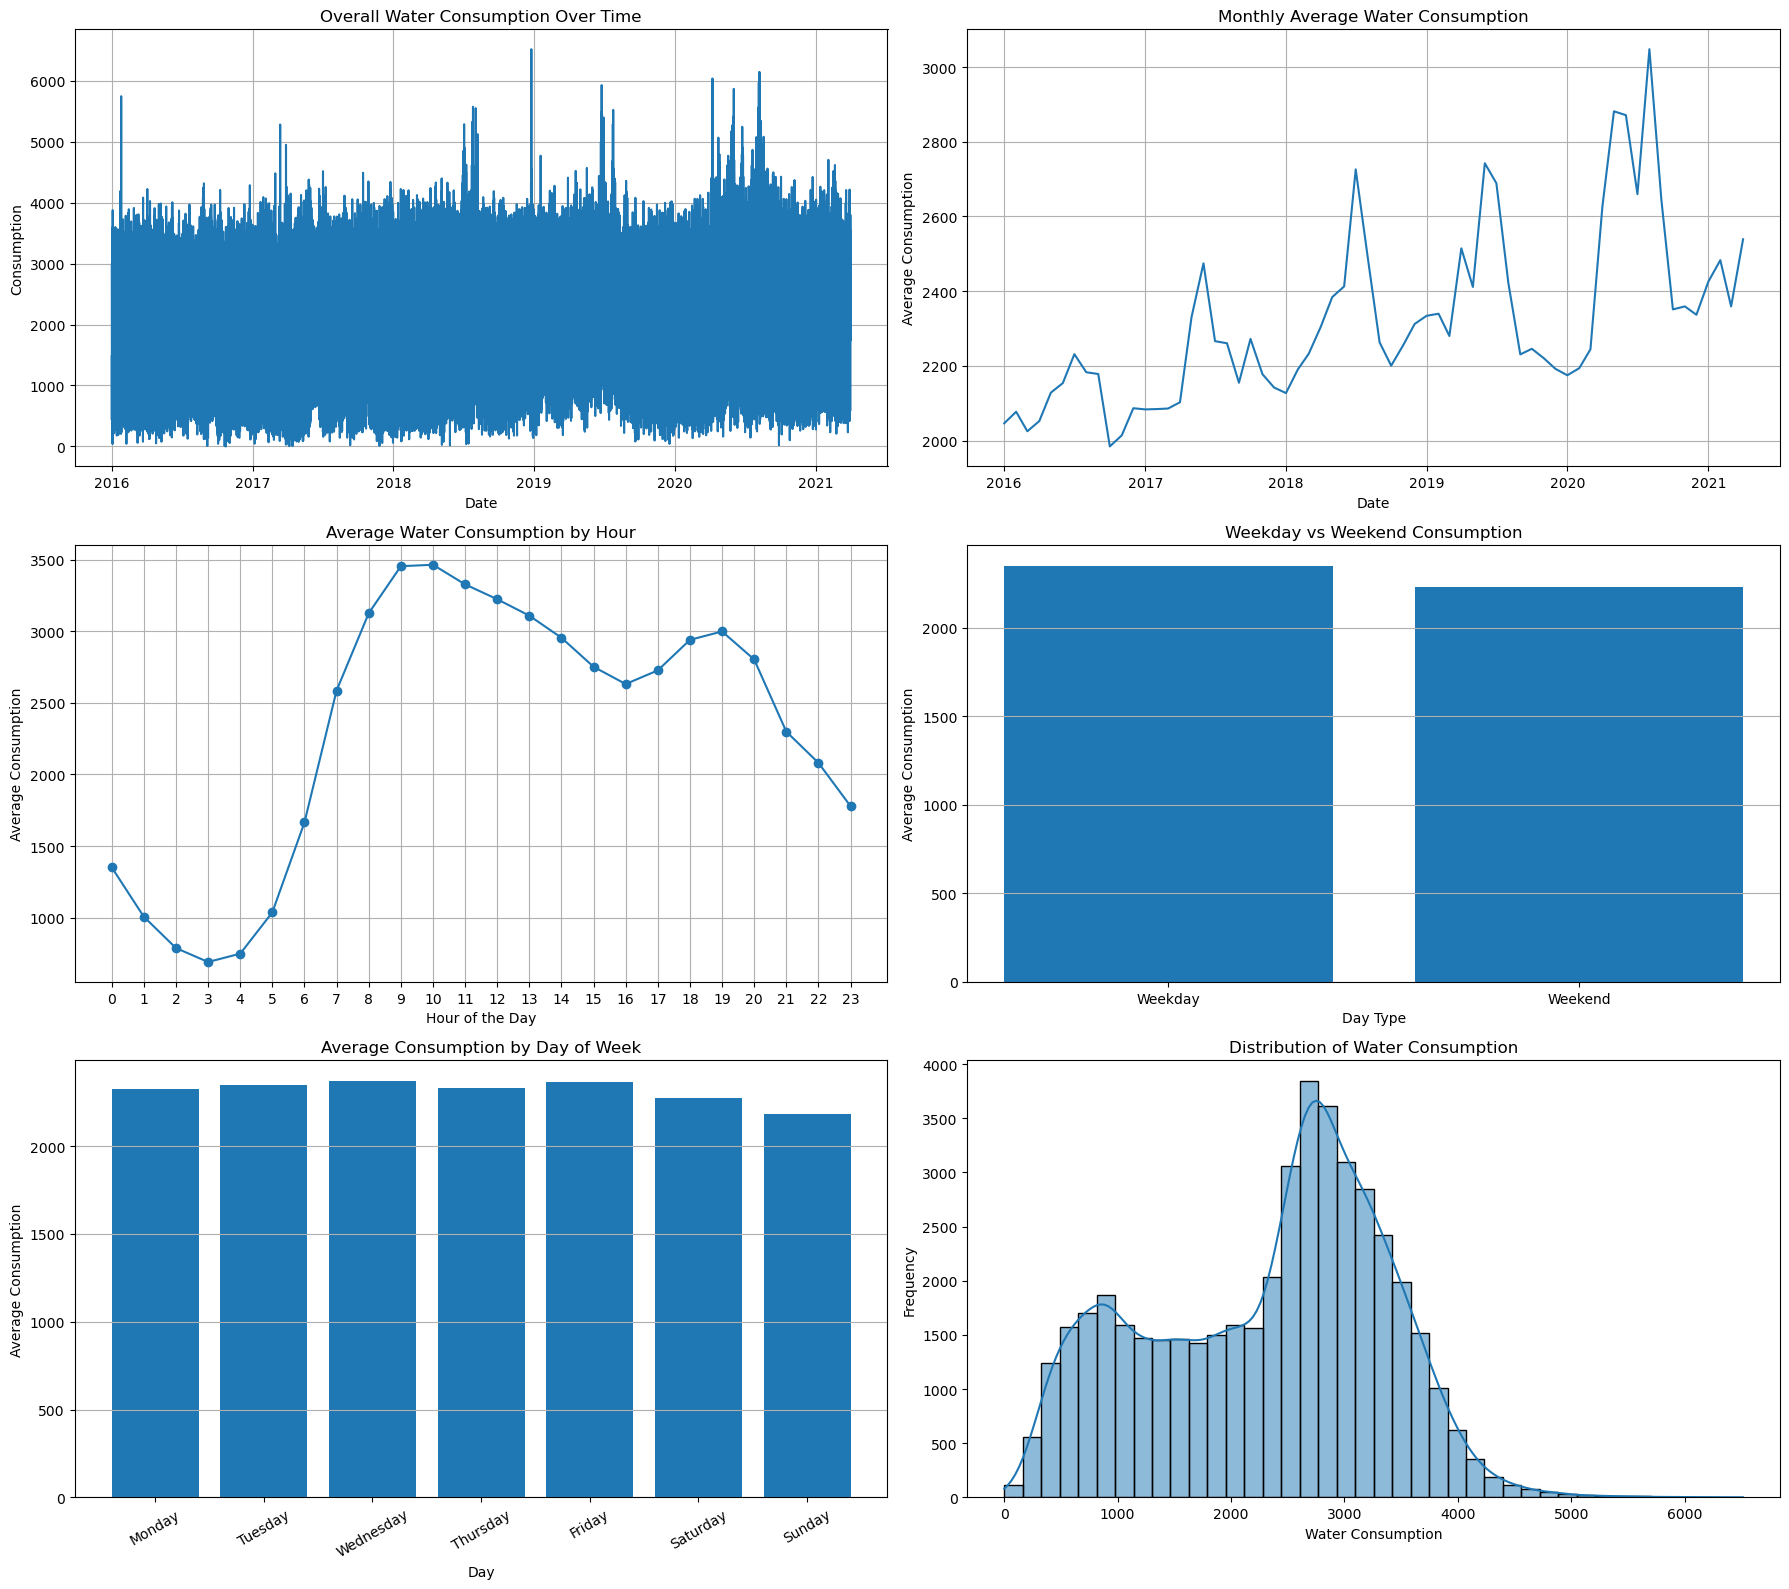

EDA SUMMARY
----------------------------------------

Average Consumption: 2314.3425443169967
Minimum Consumption: 1
Maximum Consumption: 6514

Highest Demand Hour: 10
Lowest Demand Hour: 3

Weekday Average: 2349.183972019465
Weekend Average: 2227.238975060827

Highest Demand Day: Wednesday
Lowest Demand Day: Sunday


In [16]:

# ==========================================
# SMART WATER MANAGEMENT SYSTEM
# COMPLETE EDA VISUALIZATIONS
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(18, 16))

# 1. Overall Water Consumption Over Time
axes[0, 0].plot(df['Datetime'], df['Consumption'])
axes[0, 0].set_title('Overall Water Consumption Over Time')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Consumption')
axes[0, 0].grid(True)

# 2. Monthly Average Water Consumption
monthly_consumption = (
    df.set_index('Datetime')['Consumption']
    .resample('MS').mean()
)

axes[0, 1].plot(monthly_consumption.index,
                monthly_consumption.values)
axes[0, 1].set_title('Monthly Average Water Consumption')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Average Consumption')
axes[0, 1].grid(True)

# 3. Hourly Average Water Consumption
hourly_consumption = df.groupby('Hour_Number')['Consumption'].mean()

axes[1, 0].plot(hourly_consumption.index,
                hourly_consumption.values,
                marker='o')
axes[1, 0].set_title('Average Water Consumption by Hour')
axes[1, 0].set_xlabel('Hour of the Day')
axes[1, 0].set_ylabel('Average Consumption')
axes[1, 0].set_xticks(range(24))
axes[1, 0].grid(True)

# 4. Weekday vs Weekend Consumption
weekend_consumption = df.groupby('IsWeekend')['Consumption'].mean()

axes[1, 1].bar(
    ['Weekday', 'Weekend'],
    weekend_consumption.values
)
axes[1, 1].set_title('Weekday vs Weekend Consumption')
axes[1, 1].set_xlabel('Day Type')
axes[1, 1].set_ylabel('Average Consumption')
axes[1, 1].grid(axis='y')

# 5. Average Consumption by Day of the Week
daily_consumption = df.groupby('DayOfWeek')['Consumption'].mean()

day_names = ['Monday', 'Tuesday', 'Wednesday',
             'Thursday', 'Friday', 'Saturday', 'Sunday']

axes[2, 0].bar(day_names, daily_consumption.values)
axes[2, 0].set_title('Average Consumption by Day of Week')
axes[2, 0].set_xlabel('Day')
axes[2, 0].set_ylabel('Average Consumption')
axes[2, 0].tick_params(axis='x', rotation=30)
axes[2, 0].grid(axis='y')

# 6. Distribution of Water Consumption
sns.histplot(
    df['Consumption'],
    bins=40,
    kde=True,
    ax=axes[2, 1]
)
axes[2, 1].set_title('Distribution of Water Consumption')
axes[2, 1].set_xlabel('Water Consumption')
axes[2, 1].set_ylabel('Frequency')

# Adjust layout
plt.tight_layout()
plt.show()

# Display important numerical observations
print("EDA SUMMARY")
print("-" * 40)

print("\nAverage Consumption:", df['Consumption'].mean())
print("Minimum Consumption:", df['Consumption'].min())
print("Maximum Consumption:", df['Consumption'].max())

print("\nHighest Demand Hour:",
      hourly_consumption.idxmax())

print("Lowest Demand Hour:",
      hourly_consumption.idxmin())

print("\nWeekday Average:", weekend_consumption.loc[0])
print("Weekend Average:", weekend_consumption.loc[1])

print("\nHighest Demand Day:",
      day_names[daily_consumption.idxmax()])

print("Lowest Demand Day:",
      day_names[daily_consumption.idxmin()])


In [17]:

# Create lag features

# Previous hour consumption
df['Consumption_Lag_1'] = df['Consumption'].shift(1)

# Previous 24 hours consumption
df['Consumption_Lag_24'] = df['Consumption'].shift(24)

# Average consumption of previous 24 hours
df['Rolling_Mean_24'] = (
    df['Consumption'].shift(1)
    .rolling(window=24)
    .mean()
)

# Display the new features
display(
    df[['Datetime', 'Consumption',
        'Consumption_Lag_1',
        'Consumption_Lag_24',
        'Rolling_Mean_24']].head(30)
)

# Check missing values created by lag features
print("\nMissing values:")
print(df[['Consumption_Lag_1',
          'Consumption_Lag_24',
          'Rolling_Mean_24']].isnull().sum())


,Datetime,Consumption,Consumption_Lag_1,Consumption_Lag_24,Rolling_Mean_24
0,2016-01-01 00:00:00,1480,NaN,NaN,NaN
1,2016-01-01 01:00:00,1362,1480.0,NaN,NaN
2,2016-01-01 02:00:00,1296,1362.0,NaN,NaN
3,2016-01-01 03:00:00,1096,1296.0,NaN,NaN
4,2016-01-01 04:00:00,810,1096.0,NaN,NaN
5,2016-01-01 05:00:00,474,810.0,NaN,NaN
6,2016-01-01 06:00:00,586,474.0,NaN,NaN
7,2016-01-01 07:00:00,437,586.0,NaN,NaN
8,2016-01-01 08:00:00,1004,437.0,NaN,NaN
9,2016-01-01 09:00:00,1652,1004.0,NaN,NaN



Missing values:
Consumption_Lag_1      1
Consumption_Lag_24    24
Rolling_Mean_24       24
dtype: int64


In [18]:
# Remove rows with missing lag feature values

df = df.dropna(
    subset=[
        'Consumption_Lag_1',
        'Consumption_Lag_24',
        'Rolling_Mean_24'
    ]
)

# Reset index
df = df.reset_index(drop=True)

# Verify missing values
print("Dataset Shape After Removing Missing Rows:", df.shape)

print("\nMissing values in lag features:")
print(df[['Consumption_Lag_1',
          'Consumption_Lag_24',
          'Rolling_Mean_24']].isnull().sum())

# Display first 5 records
display(df.head())

Dataset Shape After Removing Missing Rows: (46008, 17)

Missing values in lag features:
Consumption_Lag_1     0
Consumption_Lag_24    0
Rolling_Mean_24       0
dtype: int64


,Date,Time,Consumption,Temperature,Rain,Sun,Hour,Datetime,Year,Month,Day,DayOfWeek,Hour_Number,IsWeekend,Consumption_Lag_1,Consumption_Lag_24,Rolling_Mean_24
0,1/2/2016,00:00-01:00,957,4.4,0.0,0,00:00,2016-01-02 00:00:00,2016,1,2,5,0,1,1296.0,1480.0,1739.958333
1,1/2/2016,01:00-02:00,601,4.9,0.0,0,01:00,2016-01-02 01:00:00,2016,1,2,5,1,1,957.0,1362.0,1718.166667
2,1/2/2016,02:00-03:00,680,4.5,0.0,0,02:00,2016-01-02 02:00:00,2016,1,2,5,2,1,601.0,1296.0,1686.458333
3,1/2/2016,03:00-04:00,63,4.6,0.0,0,03:00,2016-01-02 03:00:00,2016,1,2,5,3,1,680.0,1096.0,1660.791667
4,1/2/2016,04:00-05:00,113,4.7,0.0,0,04:00,2016-01-02 04:00:00,2016,1,2,5,4,1,63.0,810.0,1617.750000


In [19]:
# Select input features for the ML model

features = [
    'Temperature',
    'Rain',
    'Sun',
    'Year',
    'Month',
    'Day',
    'DayOfWeek',
    'Hour_Number',
    'IsWeekend',
    'Consumption_Lag_1',
    'Consumption_Lag_24',
    'Rolling_Mean_24'
]

# Create feature matrix
X = df[features]

# Create target variable
y = df['Consumption']

# Display shapes
print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Feature Matrix Shape: (46008, 12)
Target Variable Shape: (46008,)

Input Features:
['Temperature', 'Rain', 'Sun', 'Year', 'Month', 'Day', 'DayOfWeek', 'Hour_Number', 'IsWeekend', 'Consumption_Lag_1', 'Consumption_Lag_24', 'Rolling_Mean_24']

Target Variable:
Consumption


In [20]:

# Split dataset chronologically (80:20)

split_index = int(len(X) * 0.80)

# Training data
X_train = X.iloc[:split_index]
y_train = y.iloc[:split_index]

# Testing data
X_test = X.iloc[split_index:]
y_test = y.iloc[split_index:]

# Display shapes
print("Training Data Shape:", X_train.shape)
print("Training Target Shape:", y_train.shape)

print("\nTesting Data Shape:", X_test.shape)
print("Testing Target Shape:", y_test.shape)

# Check date ranges
print("\nTraining Period:")
print(df['Datetime'].iloc[0], "to",
      df['Datetime'].iloc[split_index - 1])

print("\nTesting Period:")
print(df['Datetime'].iloc[split_index], "to",
      df['Datetime'].iloc[-1])


Training Data Shape: (36806, 12)
Training Target Shape: (36806,)

Testing Data Shape: (9202, 12)
Testing Target Shape: (9202,)

Training Period:
2016-01-02 00:00:00 to 2020-03-14 13:00:00

Testing Period:
2020-03-14 14:00:00 to 2021-04-01 23:00:00


In [21]:

# ==================================
# LINEAR REGRESSION MODEL
# ==================================

# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions on testing data
lr_predictions = lr_model.predict(X_test)

# Evaluate model performance
lr_mae = mean_absolute_error(y_test, lr_predictions)

lr_mse = mean_squared_error(y_test, lr_predictions)

lr_rmse = np.sqrt(lr_mse)

lr_r2 = r2_score(y_test, lr_predictions)

# Display results
print("LINEAR REGRESSION RESULTS")
print("-" * 35)

print("MAE:", round(lr_mae, 2))
print("MSE:", round(lr_mse, 2))
print("RMSE:", round(lr_rmse, 2))
print("R2 Score:", round(lr_r2, 4))


LINEAR REGRESSION RESULTS
-----------------------------------
MAE: 249.58
MSE: 115916.76
RMSE: 340.47
R2 Score: 0.9061


In [22]:

# ==================================
# RANDOM FOREST REGRESSION MODEL
# ==================================

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_mse = mean_squared_error(y_test, rf_predictions)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_predictions)

# Display results
print("RANDOM FOREST RESULTS")
print("-" * 35)

print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))


RANDOM FOREST RESULTS
-----------------------------------
MAE: 190.71
MSE: 67868.47
RMSE: 260.52
R2 Score: 0.945


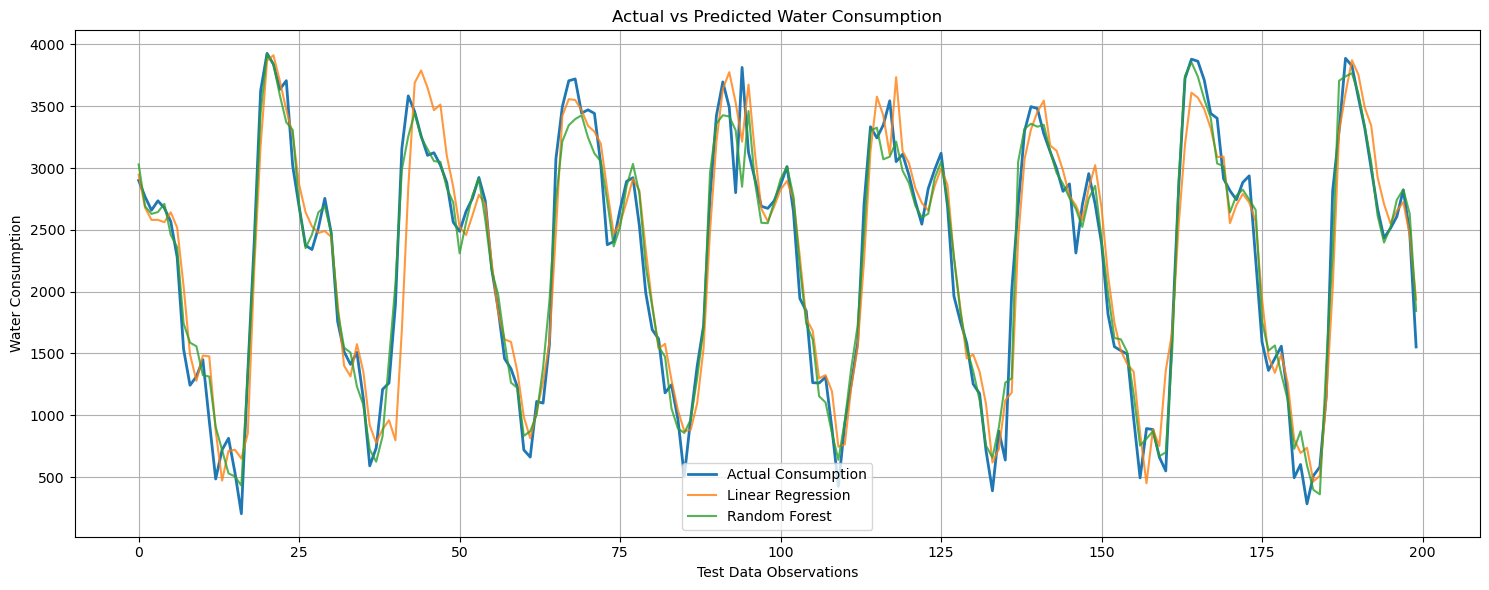

In [23]:

# Compare Actual vs Predicted Consumption

plt.figure(figsize=(15, 6))

# Display only first 200 test observations
plt.plot(
    y_test.iloc[:200].values,
    label='Actual Consumption',
    linewidth=2
)

plt.plot(
    lr_predictions[:200],
    label='Linear Regression',
    alpha=0.8
)

plt.plot(
    rf_predictions[:200],
    label='Random Forest',
    alpha=0.8
)

plt.title('Actual vs Predicted Water Consumption')
plt.xlabel('Test Data Observations')
plt.ylabel('Water Consumption')

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:
# Prepare data for Anomaly Detection

anomaly_features = [
    'Consumption',
    'Temperature',
    'Rain',
    'Sun',
    'Hour_Number',
    'DayOfWeek',
    'IsWeekend'
]

# Use chronological training and testing data
anomaly_X_train = df.iloc[:split_index][anomaly_features]
anomaly_X_test = df.iloc[split_index:][anomaly_features]

print("Anomaly Detection Training Shape:", anomaly_X_train.shape)
print("Anomaly Detection Testing Shape:", anomaly_X_test.shape)

Anomaly Detection Training Shape: (36806, 7)
Anomaly Detection Testing Shape: (9202, 7)


In [25]:

# Train Isolation Forest Model

iso_model = IsolationForest(
    n_estimators=100,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

# Train using historical training data
iso_model.fit(anomaly_X_train)

# Predict anomalies on testing data
anomaly_predictions = iso_model.predict(anomaly_X_test)

print("Isolation Forest model trained successfully!")
print("Predictions generated:", len(anomaly_predictions))


Isolation Forest model trained successfully!
Predictions generated: 9202


In [26]:

# Count Normal and Anomalous Observations

normal_count = np.sum(anomaly_predictions == 1)
anomaly_count = np.sum(anomaly_predictions == -1)

total_count = len(anomaly_predictions)

normal_percentage = (normal_count / total_count) * 100
anomaly_percentage = (anomaly_count / total_count) * 100

print("ANOMALY DETECTION RESULTS")
print("-" * 40)

print("Total Observations:", total_count)

print("Normal Observations:", normal_count)
print("Potential Anomalies:", anomaly_count)

print("Normal Percentage:", round(normal_percentage, 2), "%")
print("Anomaly Percentage:", round(anomaly_percentage, 2), "%")


ANOMALY DETECTION RESULTS
----------------------------------------
Total Observations: 9202
Normal Observations: 9067
Potential Anomalies: 135
Normal Percentage: 98.53 %
Anomaly Percentage: 1.47 %


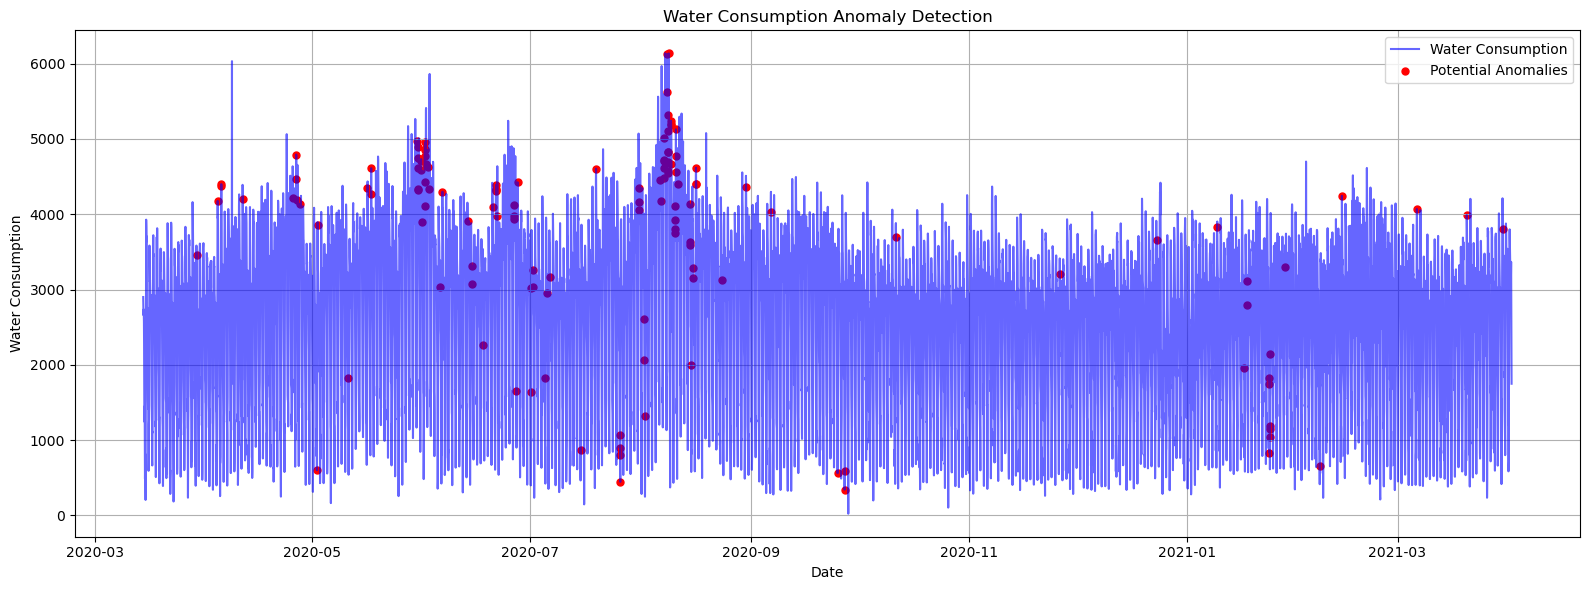

In [27]:

# Visualize Potential Water Consumption Anomalies

test_data = df.iloc[split_index:].copy()

plt.figure(figsize=(16, 6))

# Plot actual water consumption
plt.plot(
    test_data['Datetime'],
    test_data['Consumption'],
    label='Water Consumption',
    color='blue',
    alpha=0.6
)

# Highlight normal observations
normal_mask = anomaly_predictions == 1

# Highlight anomalous observations
anomaly_mask = anomaly_predictions == -1

plt.scatter(
    test_data['Datetime'].iloc[np.where(anomaly_mask)[0]],
    test_data['Consumption'].iloc[np.where(anomaly_mask)[0]],
    color='red',
    label='Potential Anomalies',
    s=25
)

plt.title('Water Consumption Anomaly Detection')
plt.xlabel('Date')
plt.ylabel('Water Consumption')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [28]:

# Extract Potential Anomaly Records

anomaly_records = test_data.iloc[
    np.where(anomaly_predictions == -1)[0]
].copy()

# Select important columns
anomaly_records = anomaly_records[
    [
        'Datetime',
        'Consumption',
        'Temperature',
        'Rain',
        'Sun',
        'Hour_Number',
        'DayOfWeek'
    ]
]

# Display 20 highest consumption anomalies
print("TOP 20 HIGH-CONSUMPTION ANOMALIES")

display(
    anomaly_records
    .sort_values(by='Consumption', ascending=False)
    .head(20)
)


TOP 20 HIGH-CONSUMPTION ANOMALIES


,Datetime,Consumption,Temperature,Rain,Sun,Hour_Number,DayOfWeek
40340,2020-08-08 20:00:00,6137,29.7,0.0,0,20,5
40330,2020-08-08 10:00:00,6129,29.0,0.0,9,10,5
40331,2020-08-08 11:00:00,5618,32.0,0.0,10,11,5
40332,2020-08-08 12:00:00,5324,33.6,0.0,10,12,5
40355,2020-08-09 11:00:00,5242,29.7,0.0,7,11,6
40356,2020-08-09 12:00:00,5195,31.9,0.0,9,12,6
40354,2020-08-09 10:00:00,5190,27.8,0.0,6,10,6
40388,2020-08-10 20:00:00,5129,28.7,0.0,1,20,0
40333,2020-08-08 13:00:00,5106,34.8,0.0,10,13,5
40307,2020-08-07 11:00:00,5015,31.4,0.0,10,11,4


TOP 15 DAYS WITH MOST ANOMALIES


,Date,Anomaly_Count
35,2020-08-08,10
13,2020-06-01,7
37,2020-08-10,7
53,2021-01-24,7
11,2020-05-30,6
34,2020-08-07,5
21,2020-06-21,5
36,2020-08-09,4
12,2020-05-31,4
24,2020-07-01,4


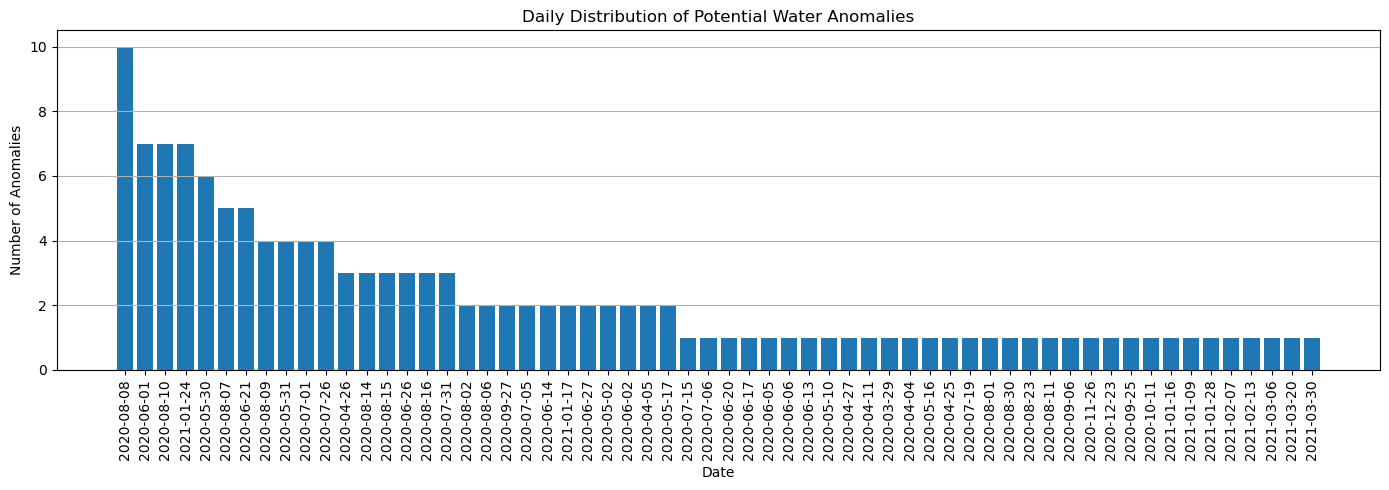

In [29]:

# Count anomalies by date

anomaly_records['Date'] = anomaly_records['Datetime'].dt.date

daily_anomalies = (
    anomaly_records.groupby('Date')
    .size()
    .reset_index(name='Anomaly_Count')
    .sort_values(by='Anomaly_Count', ascending=False)
)

print("TOP 15 DAYS WITH MOST ANOMALIES")

display(daily_anomalies.head(15))

# Visualize daily anomaly counts

plt.figure(figsize=(14, 5))

plt.bar(
    daily_anomalies['Date'].astype(str),
    daily_anomalies['Anomaly_Count']
)

plt.title('Daily Distribution of Potential Water Anomalies')
plt.xlabel('Date')
plt.ylabel('Number of Anomalies')
plt.xticks(rotation=90)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [30]:

# Compare Normal and Anomalous Consumption

normal_consumption = test_data.loc[
    anomaly_predictions == 1, 'Consumption'
]

anomalous_consumption = test_data.loc[
    anomaly_predictions == -1, 'Consumption'
]

print("CONSUMPTION COMPARISON")
print("-" * 40)

print("Normal Average Consumption:",
      round(normal_consumption.mean(), 2))

print("Anomalous Average Consumption:",
      round(anomalous_consumption.mean(), 2))

print("Normal Maximum Consumption:",
      normal_consumption.max())

print("Anomalous Maximum Consumption:",
      anomalous_consumption.max())

print("Normal Minimum Consumption:",
      normal_consumption.min())

print("Anomalous Minimum Consumption:",
      anomalous_consumption.min())


CONSUMPTION COMPARISON
----------------------------------------
Normal Average Consumption: 2556.5
Anomalous Average Consumption: 3674.77
Normal Maximum Consumption: 6138
Anomalous Maximum Consumption: 6137
Normal Minimum Consumption: 21
Anomalous Minimum Consumption: 340


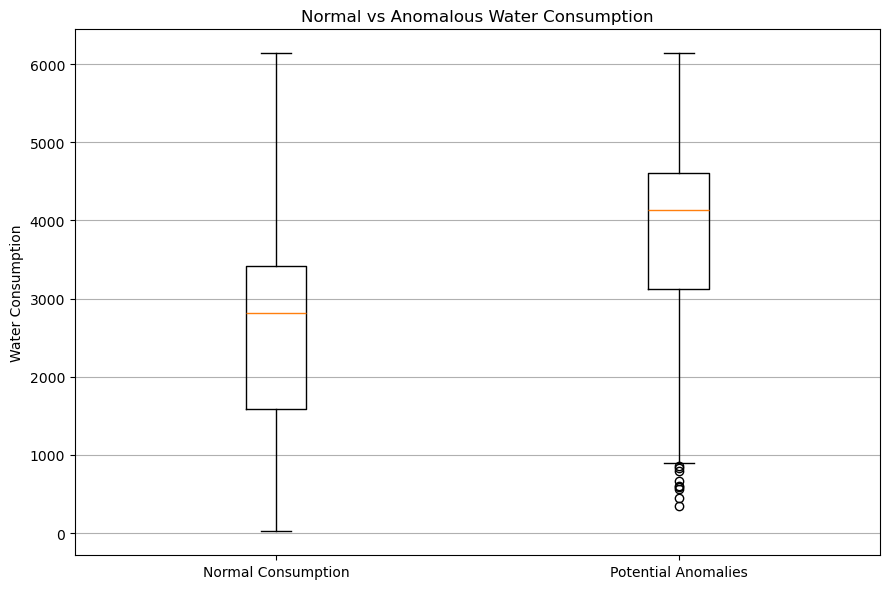

In [31]:

# Compare Normal and Anomalous Consumption

plt.figure(figsize=(9, 6))

plt.boxplot(
    [
        normal_consumption,
        anomalous_consumption
    ],
    labels=['Normal Consumption', 'Potential Anomalies']
)

plt.title('Normal vs Anomalous Water Consumption')
plt.ylabel('Water Consumption')
plt.grid(axis='y')
plt.tight_layout()
plt.show()


In [32]:

import joblib

# Save trained models
joblib.dump(lr_model, 'linear_regression_model.pkl')
joblib.dump(rf_model, 'random_forest_model.pkl')
joblib.dump(iso_model, 'isolation_forest_model.pkl')

print("All models saved successfully!")

print("1. Linear Regression Model")
print("2. Random Forest Model")
print("3. Isolation Forest Model")


All models saved successfully!
1. Linear Regression Model
2. Random Forest Model
3. Isolation Forest Model


In [33]:

# Load saved models

loaded_lr = joblib.load('linear_regression_model.pkl')
loaded_rf = joblib.load('random_forest_model.pkl')
loaded_iso = joblib.load('isolation_forest_model.pkl')

# Test forecasting model
sample_forecast = loaded_rf.predict(X_test.iloc[:5])

# Test anomaly detection model
sample_anomalies = loaded_iso.predict(anomaly_X_test.iloc[:5])

print("All models loaded successfully!")
print("\nSample Water Demand Predictions:")
print(sample_forecast)

print("\nSample Anomaly Predictions:")
print(sample_anomalies)


All models loaded successfully!

Sample Water Demand Predictions:
[3029.31 2691.37 2629.15 2644.37 2710.86]

Sample Anomaly Predictions:
[1 1 1 1 1]


RANDOM FOREST FEATURE IMPORTANCE


,Feature,Importance
10,Consumption_Lag_24,0.714963
9,Consumption_Lag_1,0.152718
7,Hour_Number,0.091618
11,Rolling_Mean_24,0.009405
6,DayOfWeek,0.008377
0,Temperature,0.006533
5,Day,0.004545
4,Month,0.003708
8,IsWeekend,0.003271
3,Year,0.003122


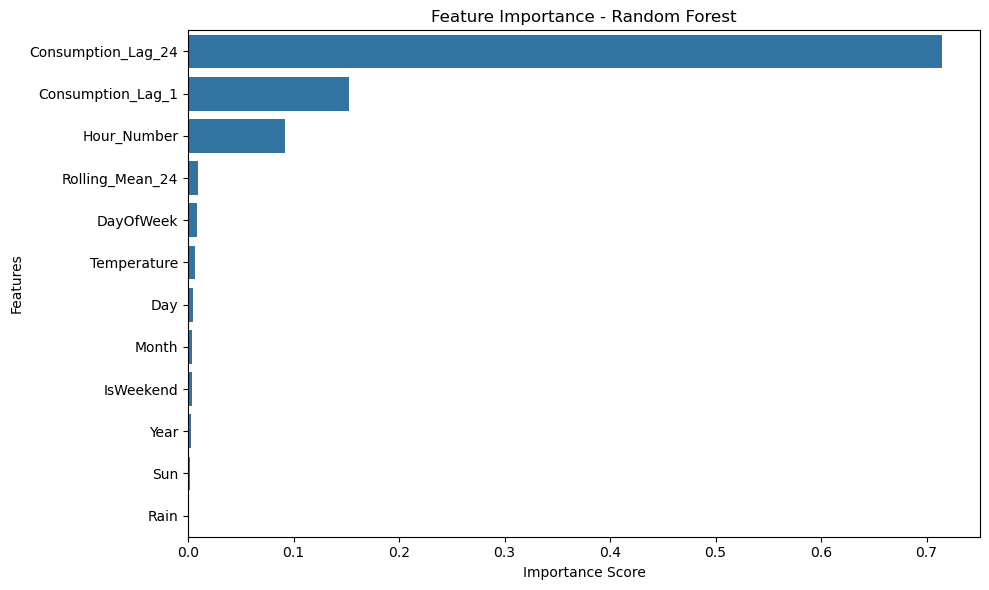

In [34]:

# Random Forest Feature Importance

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
display(feature_importance)

# Visualize feature importance

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


In [35]:
!streamlit --version

Streamlit, version 1.45.1


In [36]:
import os

print("CURRENT PROJECT FOLDER:")
print(os.getcwd())

print("\nPROJECT FILES:")
for file in os.listdir():
    print(file)

CURRENT PROJECT FOLDER:
C:\Users\Admin\Smart_Water_Management

PROJECT FILES:
.ipynb_checkpoints
isolation_forest_model.pkl
linear_regression_model.pkl
random_forest_model.pkl
Smart_Water_Management.ipynb
waterconsumption_noNaN_fixedTimechange.csv
